# ACCESS-OM3 and ACCESS-OM2 timeseries
Includes both scalar variables and spatial averages of 2d variables.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_era_iaf-test1-1d86aa55/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/"
nbname = "timeseries.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file, get_exptname_from_path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
%matplotlib inline
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()  # conda env workaround; no-op on healthy envs

import pandas as pd
import intake
import xarray as xr
import numpy as np
import cf_xarray as cfxr
import pint_xarray
from pint import application_registry as ureg
import cf_xarray.units
import cftime
import xgcm
import os

import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft

from dask.distributed import Client

In [5]:
xr.set_options(keep_attrs=True); # cf_xarray works best when xarray keeps attributes by default

In [6]:
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 190.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34227,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35783,Total threads: 1
Dashboard: http://127.0.0.1:34861/status,Memory: 11.88 GiB
Nanny: tcp://127.0.0.1:39625,


In [7]:
thisdir = './'

In [8]:
IAF = esm_file.find('iaf') > 0
IAF

True

### Define data sources

In [9]:
catalogs = [
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
                esm_file,  # the CM3/OM3 experiment under test -- already includes CM3 when esm_file is a CM3 path
                "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json",   # 100km RYF spin-up
            ]
catalogs

['/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
 '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json',
 '/g/data/ol01/outputs/access-om3-100km/MC_100km_era_iaf-test1-1d86aa55/experiment_datastore.json',
 '/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c/experiment_datastore.json']

In [10]:
datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c, columns_with_iterables=['variable'])
              for c in catalogs }
datastores

{'MC_25km_jra_iaf-1.0-beta-5165c0f8': <datastore catalog with 22 dataset(s) from 6042 asset(s)>,
 'MC_25km_jra_iaf+wombatlite-test3v2-00532b88': <datastore catalog with 24 dataset(s) from 32927 asset(s)>,
 'MC_100km_era_iaf-test1-1d86aa55': <experiment_datastore catalog with 19 dataset(s) from 6164 asset(s)>,
 'MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c': <experiment_datastore catalog with 15 dataset(s) from 8540 asset(s)>}

In [11]:
if model_name == "ACCESS-CM3":
    # ACCESS-CM2 cj877 control run reference (as in other CM3 notebooks).
    # Its scalar diagnostics use the same variable names as the OM2 catalog.
    om2expt = 'cj877'
    import glob
    _cm2_files = sorted(glob.glob('/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-scalar-1-daily-ym_*.nc'))
    om2cat = xr.open_mfdataset(_cm2_files, combine="by_coords", parallel=True, chunks={"time": 181},
                               decode_timedelta=False, use_cftime=True,
                               data_vars="minimal", coords="minimal", compat="override")
else:
    # ACCESS-OM2-025 experiment
    # use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258
    if IAF:
        om2expt = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2expt = '025deg_jra55_ryf9091_gadi'
    om2cat = intake.cat.access_nri[om2expt]

### Load grid data
This is needed for xgcm so we can get spatial averages of non-scalar data.

In [12]:
exptname = get_exptname_from_path(esm_file)
# filename regex matches om3 and cm3 static files
static = xr.open_dataset(datastores[exptname].search(filename=".*mom6.static.nc").df.loc[0, "path"]).drop_vars("time")

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e814ade0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e8437770>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e8437050>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d63990c110>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e8436a80>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e8437d10>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14d5e296e2d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [13]:
# See https://xgcm.readthedocs.io/en/latest/xgcm-examples/03_MOM6/#xgcm-grid-definition
symmetric = True  # True for ACCESS-OM3 2025.08.000 and later

if symmetric:  # ACCESS-OM3 version 2025.08.000 and later: one more q point than h points
    coords={
        'X': {'center': 'xh', 'outer': 'xq'},
        'Y': {'center': 'yh', 'outer': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }
else:  # ACCESS-OM3 versions prior to 2025.08.000: equal number of q and h points
    coords={
        'X': {'center': 'xh', 'right': 'xq'},
        'Y': {'center': 'yh', 'right': 'yq'},
        # 'Z': { 'inner': 'zl', 'outer': 'zi'}
    }

grid = xgcm.Grid(
    static,
    coords=coords,
    metrics = {
        ('X',): ['dxt', 'dxCu', 'dxCv'], # X distances
        ('Y',): ['dyt', 'dyCu', 'dyCv'], # Y distances
        ('X', 'Y'): ['areacello', 'areacello_cu', 'areacello_cv', 'areacello_bu'] # Areas
    },
    periodic=['X'],
    autoparse_metadata=False
# Note, autoparse_metadata=False is required below for xgcm >= 0.9.0 to prevent xgcm 
# from trying to autoparse non-existent grid information from the file metadata, 
# leading to the error:
# ValueError: Found two coordinates without `c_grid_axis_shift` attribute for axis X
)

### Define list of variables and load them

In [14]:
fields = { # key is OM3 name, value is OM2 name
    # 'mlotst': 'mld',
    # keys from ncdump -h ctrl_run_25km_0.5/archive/output009/access-om3.mom6.scalar.1day.snap.1962.nc | grep double
    'masso': None, # Mass of liquid ocean
    'soga': 'salt_global_ave',
    'thetaoga': 'temp_global_ave', # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'tosga': 'temp_surface_ave',   # BUG: is OM2 potential temperature? https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3#issuecomment-3736872326
    'sosga': 'salt_surface_ave',
    'speed_max': None,
    'mlotst_max': None,
    'tos_max': None,
    'tos_min': None,
    'sos_max': None,
    'sos_min': None,
    'zos_max': None,
    'zos_min': None, 
    'total_salt_Flux_Added': None,
    'total_salt_Flux_In': None,
    'total_salt_flux': None,
    'net_fresh_water_global_adjustment': None,
    'salt_flux_global_restoring_adjustment': None,
    'total_wfo': None,
    'total_evs': None,
    'total_fsitherm': None,
    'total_precip': None,
    'total_prsn': None,
    'total_lprec': None,
    'total_ficeberg': None,
    'total_friver': None,
    'total_net_massout': None,
    'total_net_massin': None,
}
fields

{'masso': None,
 'soga': 'salt_global_ave',
 'thetaoga': 'temp_global_ave',
 'tosga': 'temp_surface_ave',
 'sosga': 'salt_surface_ave',
 'speed_max': None,
 'mlotst_max': None,
 'tos_max': None,
 'tos_min': None,
 'sos_max': None,
 'sos_min': None,
 'zos_max': None,
 'zos_min': None,
 'total_salt_Flux_Added': None,
 'total_salt_Flux_In': None,
 'total_salt_flux': None,
 'net_fresh_water_global_adjustment': None,
 'salt_flux_global_restoring_adjustment': None,
 'total_wfo': None,
 'total_evs': None,
 'total_fsitherm': None,
 'total_precip': None,
 'total_prsn': None,
 'total_lprec': None,
 'total_ficeberg': None,
 'total_friver': None,
 'total_net_massout': None,
 'total_net_massin': None}

In [15]:
# from https://github.com/COSIMA/cosima-recipes/blob/main/Cooking-Lessons-101-Tutorials/ACCESS-NRI_Intake_Catalog.ipynb
# Speeding up opening your datasets
# Try passing the following argument to your to_dask or to_dataset_dict call:
# See the xarray documentation on Reading multi-file datasets for more details about these arguments.
# https://docs.xarray.dev/en/stable/user-guide/io.html#reading-multi-file-datasets

xarray_combine_by_coords_kwargs=dict(
    compat="override",
    data_vars="minimal",
    coords="minimal"
)

In [16]:
# load data, with lots of workarounds for disambiguation
data = dict()
for k, om2 in fields.items():
    print(k)
    # d = [ ds.search(variable=k).to_dataset_dict(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for ds in datastores ]
    try:
        d = { n: ds.search(variable=k) for n, ds in datastores.items() }
        d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
    except ValueError:
        try:
            d = { n: ds.search(variable=k, frequency='1mon', variable_cell_methods='.*time: mean.*') for n, ds in datastores.items() }
            d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
        except:
            try:
                d = { n: ds.search(variable=k, variable_cell_methods='.*time: mean.*') for n, ds in datastores.items() }
                d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
            except:
                try:
                    d = { n: ds.search(variable=k, variable_cell_methods='.*time: point.*') for n, ds in datastores.items() }
                    d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                except:
                    try:
                        d = { n: ds.search(variable=k, variable_cell_methods='.*time: min.*') for n, ds in datastores.items() }
                        d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                    except:
                        try:
                            d = { n: ds.search(variable=k, variable_cell_methods='.*time: max.*') for n, ds in datastores.items() }
                            d = { n: ds.to_dask(xarray_combine_by_coords_kwargs=xarray_combine_by_coords_kwargs) for n, ds in d.items() if ds } # avoid .to_dask() for empty datasets
                        except:
                            print(f'{k} failed')
                            continue
    if om2 is None: # add reference model data, with variable name changed to match om3
        d2 = {}
    elif model_name == "ACCESS-CM3":
        cm2_da = om2cat[[om2]].isel(scalar_axis=0, drop=True).rename({om2: k})  # drop dummy scalar_axis dim
        # relabel cj877 (cftime, model years) onto CM3's own datetime64 time axis,
        # matching elapsed time since each run's start (both are daily)
        _cm3t = d[exptname].time
        n = min(cm2_da.sizes["time"], _cm3t.sizes["time"])
        cm2_da = cm2_da.isel(time=slice(None, n)).assign_coords(time=("time", _cm3t.isel(time=slice(None, n)).values))
        d2 = {om2expt: cm2_da}
    else:
        # d[om2expt] = om2cat.search(variable=om2).to_dask().rename({om2: k})
        d2 = {om2expt: om2cat.search(variable=om2, frequency=d[list(d.keys())[0]].attrs['intake_esm_attrs:frequency']).to_dask().rename({om2: k})}
    # if d:
    #     data[k] = xr.concat(d, 'time')
    # else:
    #     print(f'no data for {k}')
    # break
    data[k] = d2 | d
    # break

if IAF:
    for vname, d in data.items():
        for expt in d.keys():
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# RYF spin-up runs use a synthetic calendar (e.g. starting ~1900s) unrelated to real
# forcing dates, so their time axis does not overlap the IAF experiments at all.
# Relabel onto the primary experiment's real time axis so the RYF run plots on the
# same timescale as the IAF runs. Only applied to the RYF experiment.
_ryf_expt = "MC_100km_jra_ryf+wombatlite-1e74abf-11f9df5c"
for _vname, _d in data.items():
    if _ryf_expt not in _d or exptname not in _d:
        continue
    _ref = _d[exptname].time
    _rds = _d[_ryf_expt]
    _n = min(_rds.sizes["time"], _ref.sizes["time"])
    _d[_ryf_expt] = (_rds.isel(time=slice(None, _n))
                         .assign_coords(time=("time", _ref.isel(time=slice(None, _n)).values)))

data

masso


soga


thetaoga


tosga


sosga


speed_max


... (19 outputs left out)

total_friver


total_net_massout


total_net_massin


{'masso': {'MC_25km_jra_iaf-1.0-beta-5165c0f8': <xarray.Dataset> Size: 333kB
  Dimensions:      (time: 20819, scalar_axis: 1)
  Coordinates:
    * time         (time) object 167kB 1958-01-02 00:00:00 ... 2015-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 167kB dask.array<chunksize=(365, 1), meta=np.ndarray>
  Attributes: (12/14)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_standard_name:  ['sea_water_mass', '', '', '', ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_a

In [17]:
data.keys()

dict_keys(['masso', 'soga', 'thetaoga', 'tosga', 'sosga', 'speed_max', 'mlotst_max', 'tos_max', 'tos_min', 'sos_max', 'sos_min', 'zos_max', 'zos_min', 'total_salt_Flux_Added', 'total_salt_Flux_In', 'total_salt_flux', 'net_fresh_water_global_adjustment', 'salt_flux_global_restoring_adjustment', 'total_wfo', 'total_evs', 'total_fsitherm', 'total_precip', 'total_prsn', 'total_lprec', 'total_ficeberg', 'total_friver', 'total_net_massout', 'total_net_massin'])

In [18]:
data

{'masso': {'MC_25km_jra_iaf-1.0-beta-5165c0f8': <xarray.Dataset> Size: 333kB
  Dimensions:      (time: 20819, scalar_axis: 1)
  Coordinates:
    * time         (time) object 167kB 1958-01-02 00:00:00 ... 2015-01-01 00:00:00
    * scalar_axis  (scalar_axis) float64 8B 0.0
  Data variables:
      masso        (time, scalar_axis) float64 167kB dask.array<chunksize=(365, 1), meta=np.ndarray>
  Attributes: (12/14)
      title:                                    ACCESS-OM3
      grid_type:                                regular
      grid_tile:                                N/A
      intake_esm_vars:                          ['masso']
      intake_esm_attrs:file_id:                 ocean.1day.scalar_axis:1
      intake_esm_attrs:frequency:               1day
      ...                                       ...
      intake_esm_attrs:variable_standard_name:  ['sea_water_mass', '', '', '', ...
      intake_esm_attrs:variable_cell_methods:   ['time: point', 'time: point', ...
      intake_esm_a

### Plot timeseries

In [19]:
# set date range
# trange = slice(cftime.DatetimeNoLeap(1900, 1, 1, 0, 0, 0, 0),
#                cftime.DatetimeNoLeap(1960, 1, 1, 0, 0, 0, 0))
trange = slice(None, None)  # all available

masso


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_01.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md


Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
soga


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_02.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
thetaoga


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_03.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
tosga


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_04.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
sosga


... (21 outputs left out)

Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_25.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
total_friver


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_26.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
total_net_massout


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_27.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.
total_net_massin


Saved /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries_28.png
Adding entry to per-notebook markdown: /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/ek4684/access-om3-paper-1-mc100era5/notebooks/mkfigs_output_MC_100km_era_iaf-test1-1d86aa55/mkmd/timeseries.md successfully.


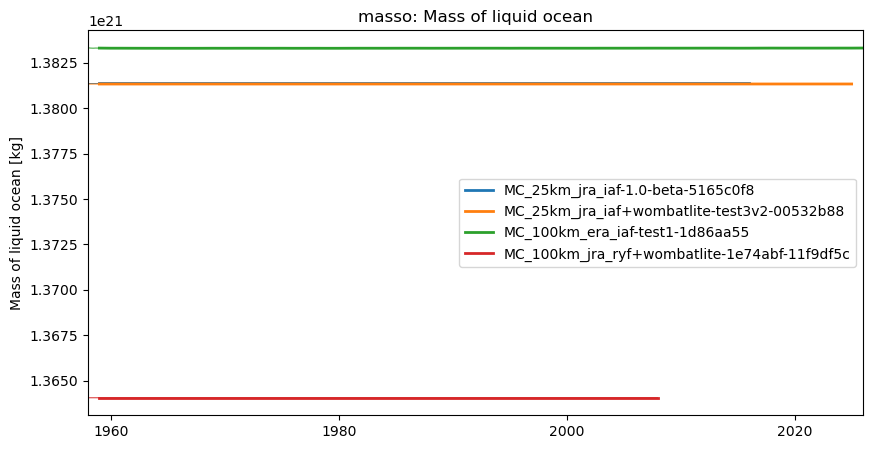

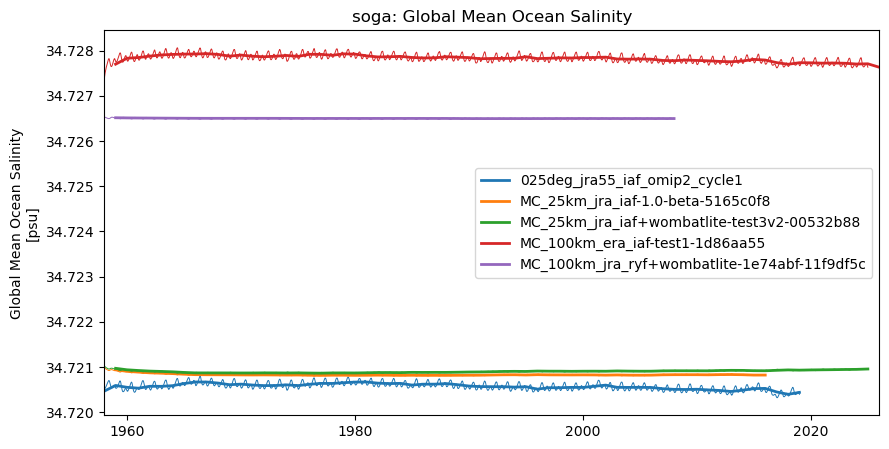

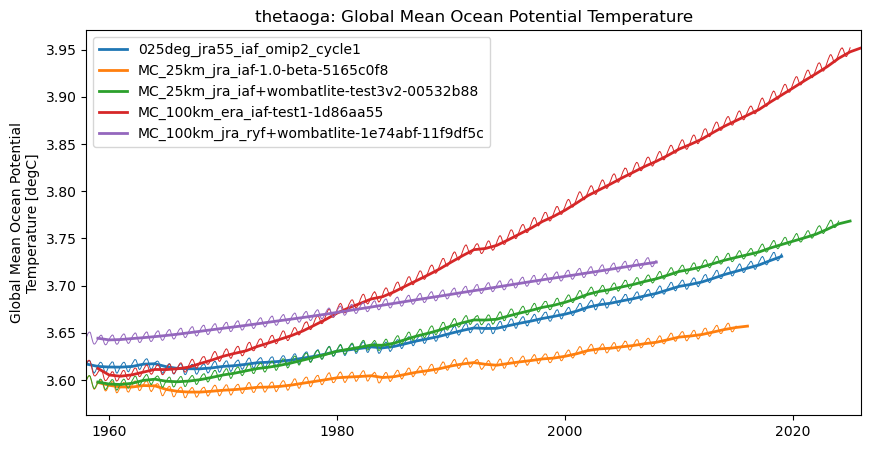

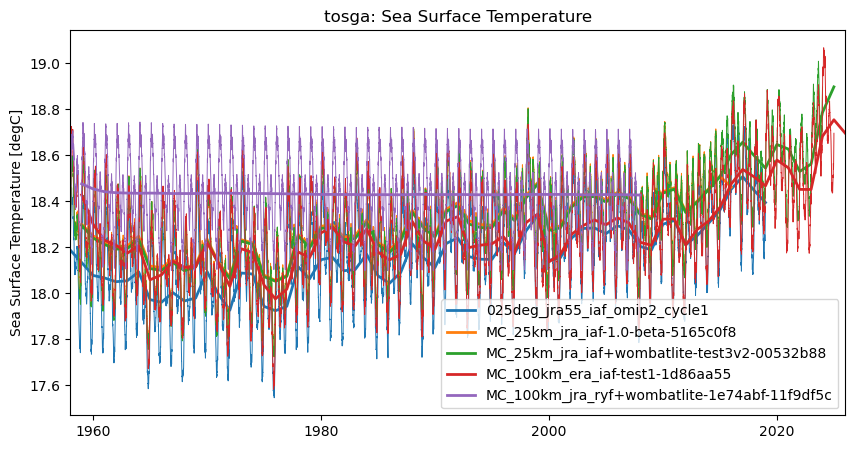

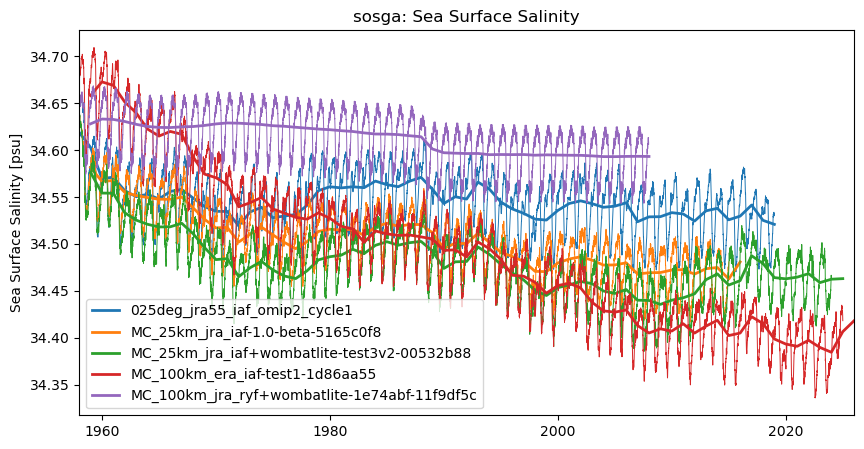

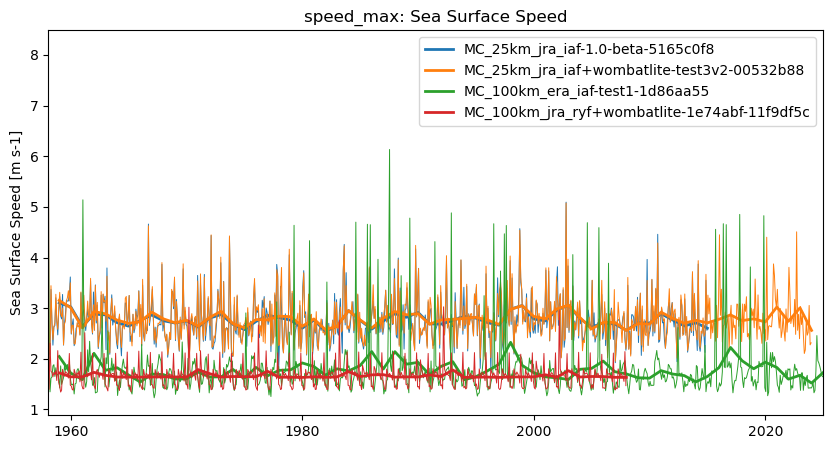

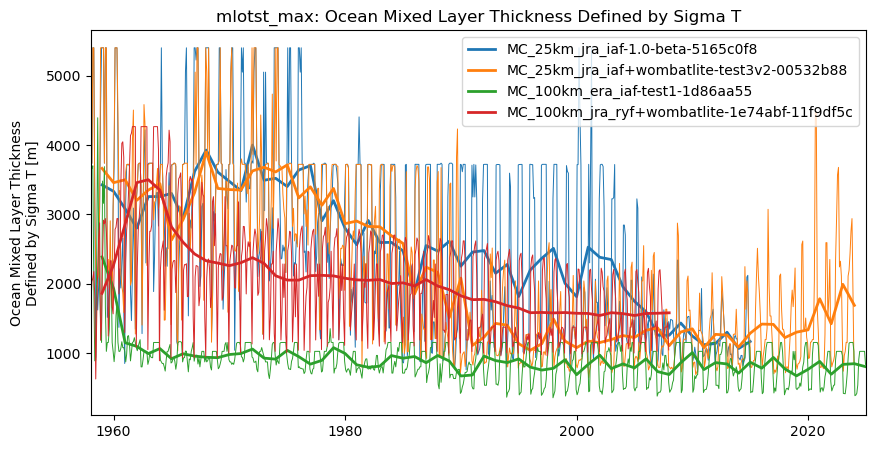

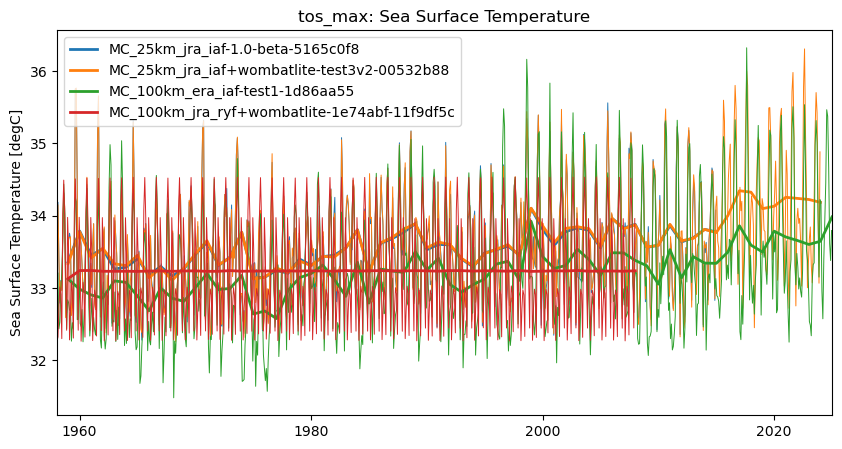

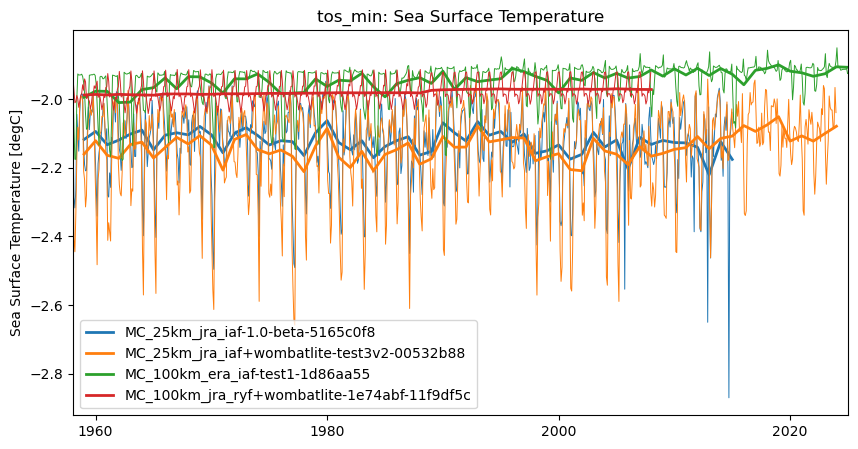

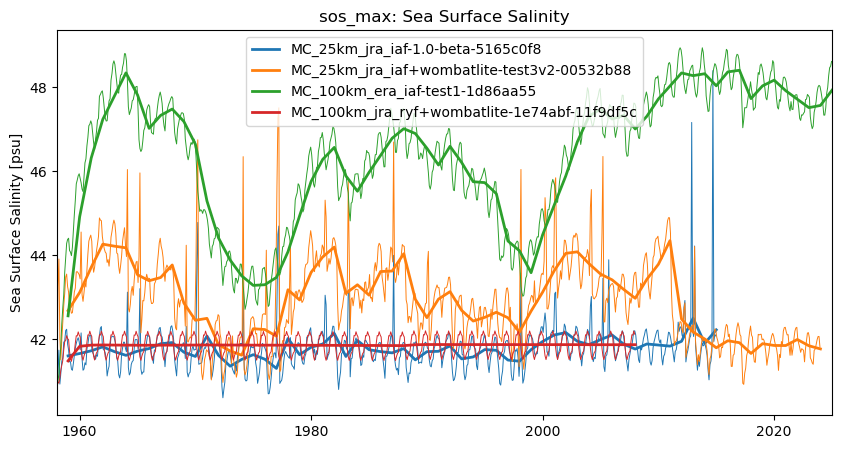

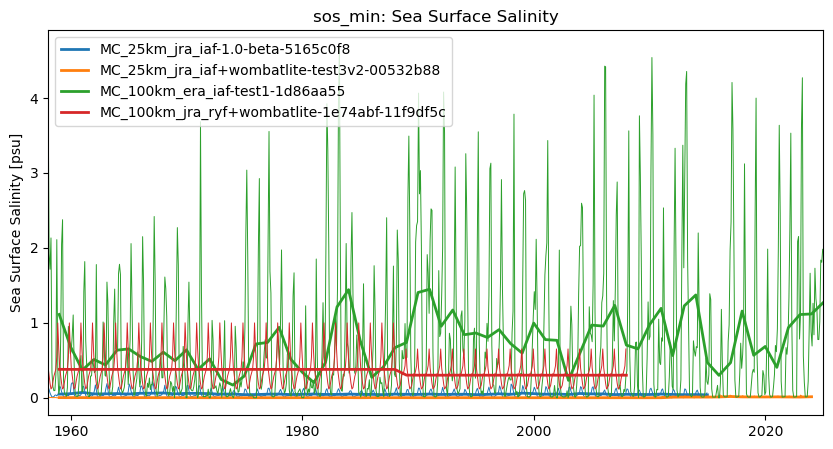

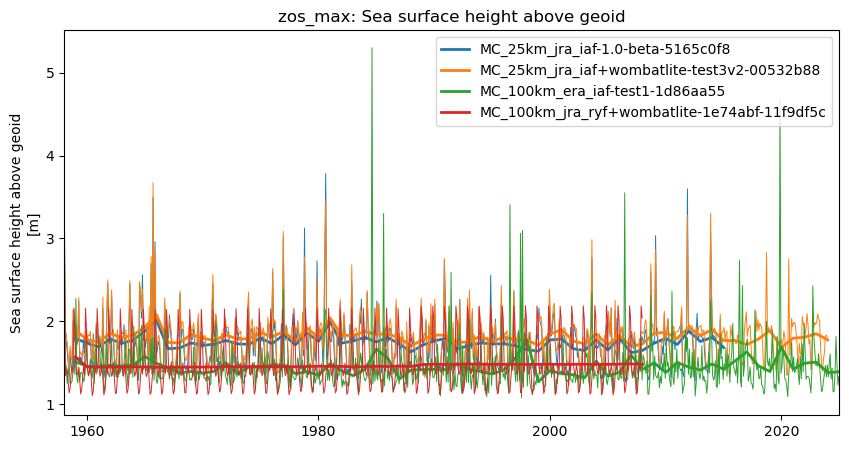

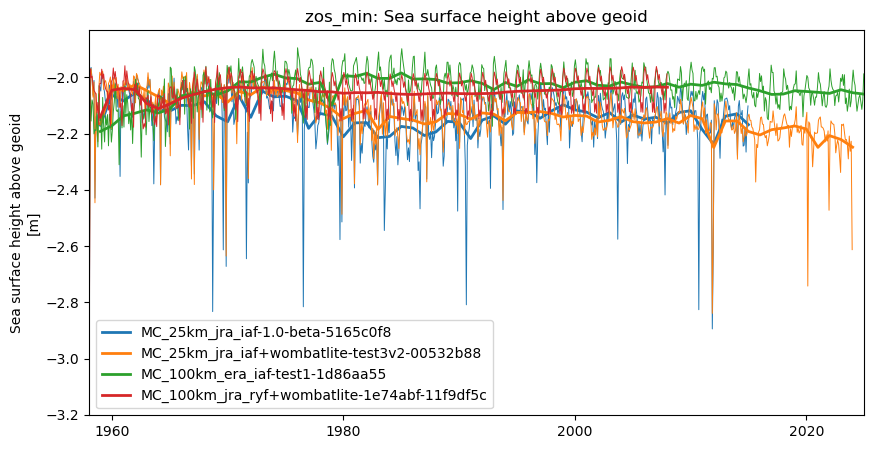

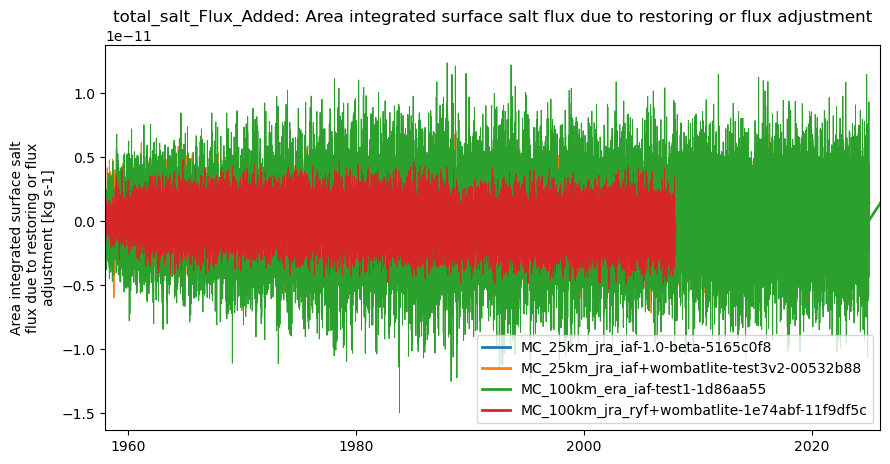

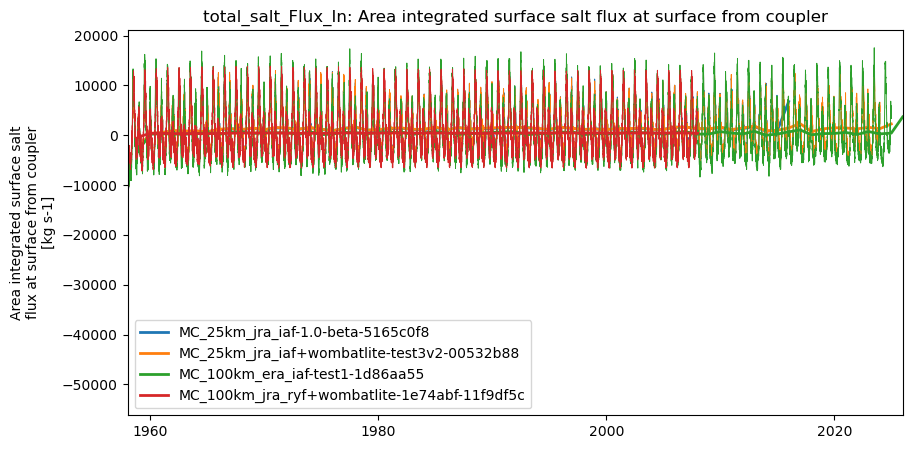

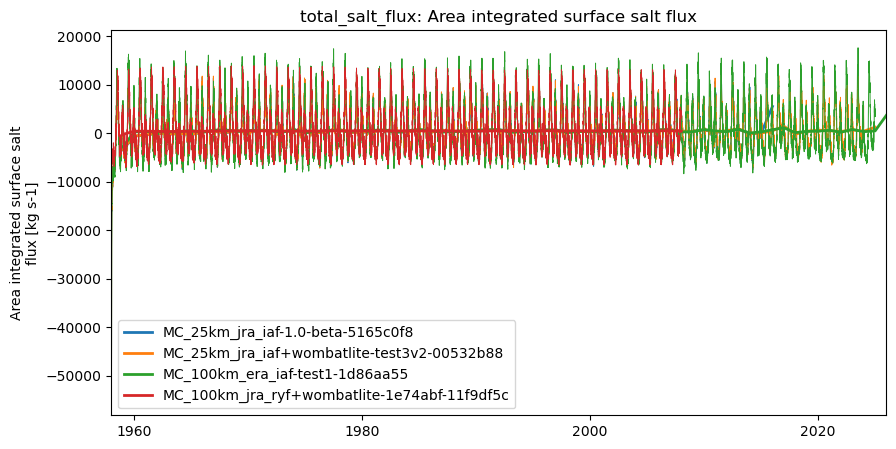

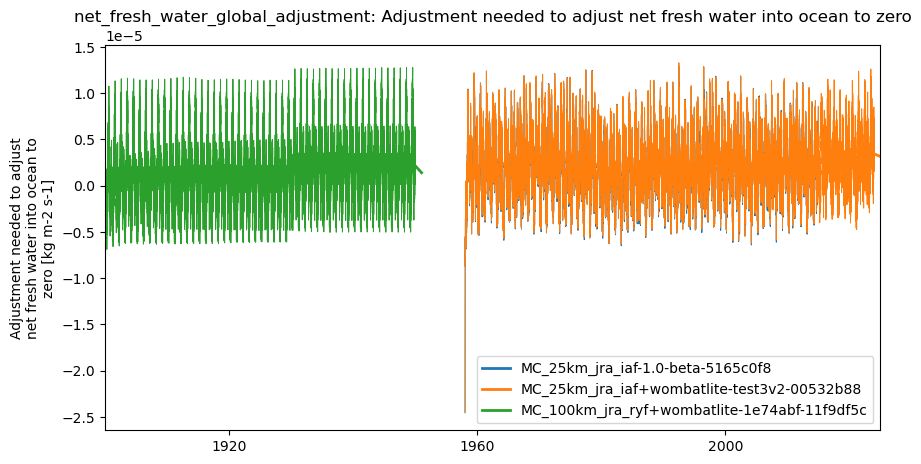

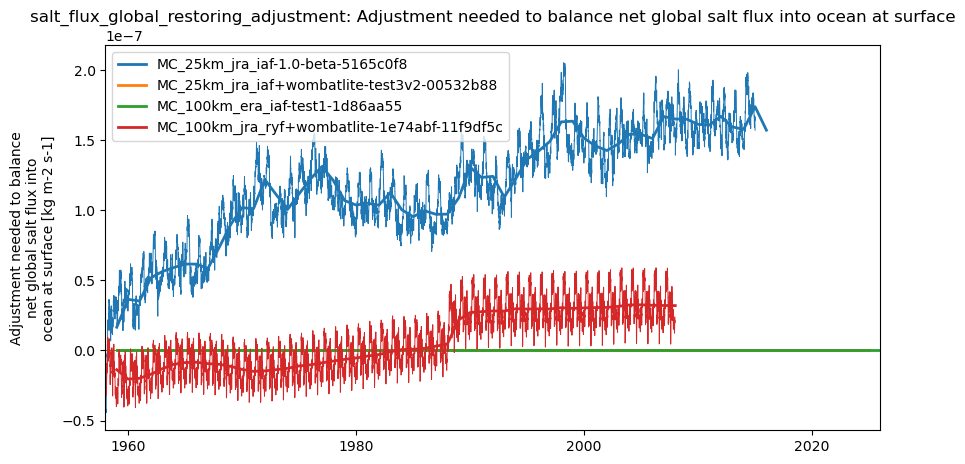

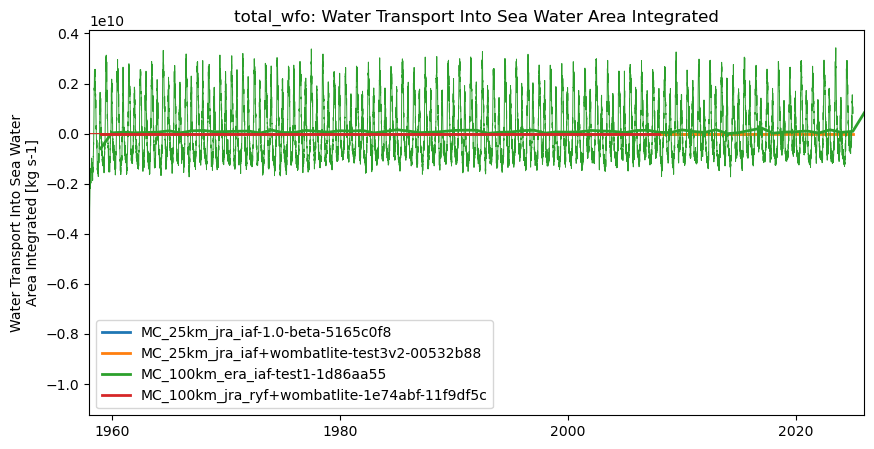

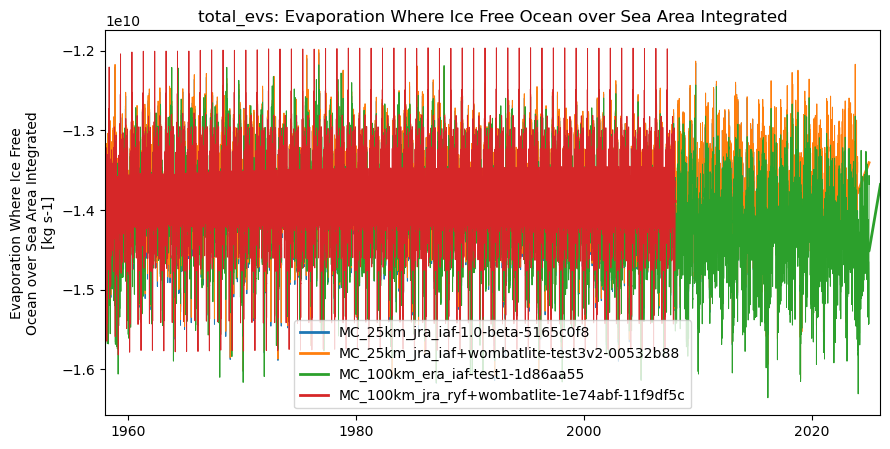

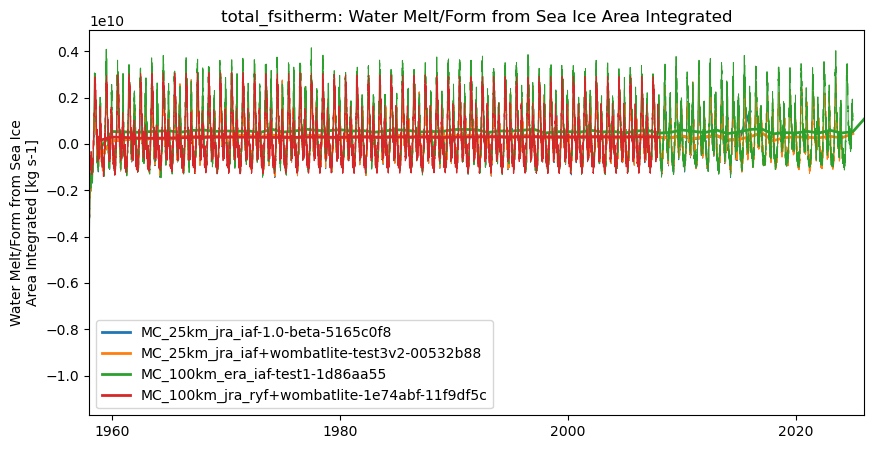

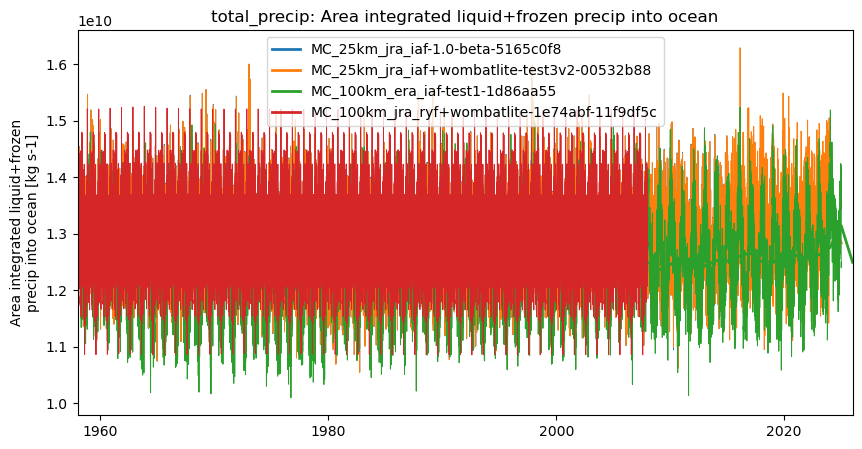

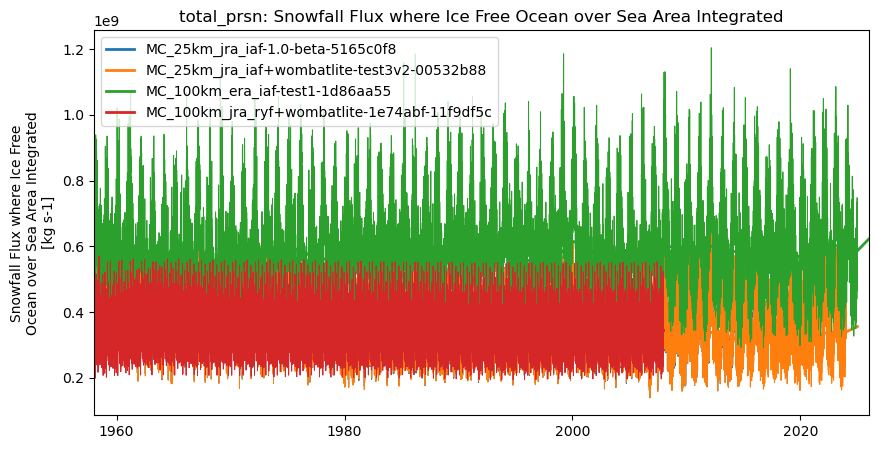

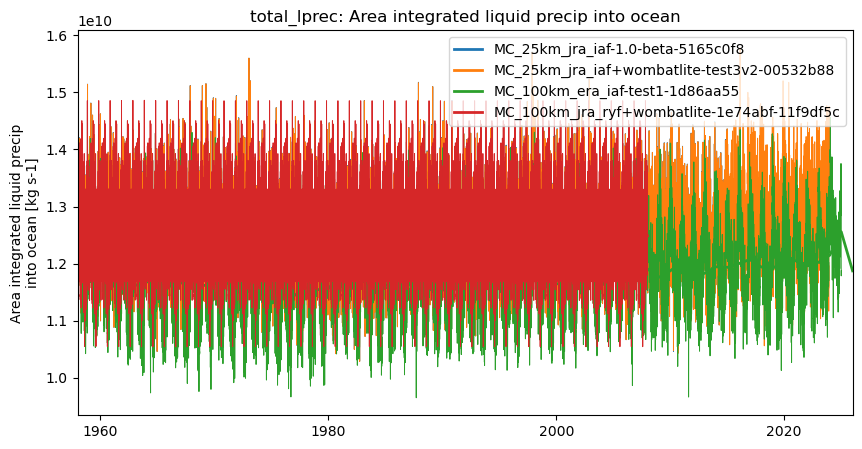

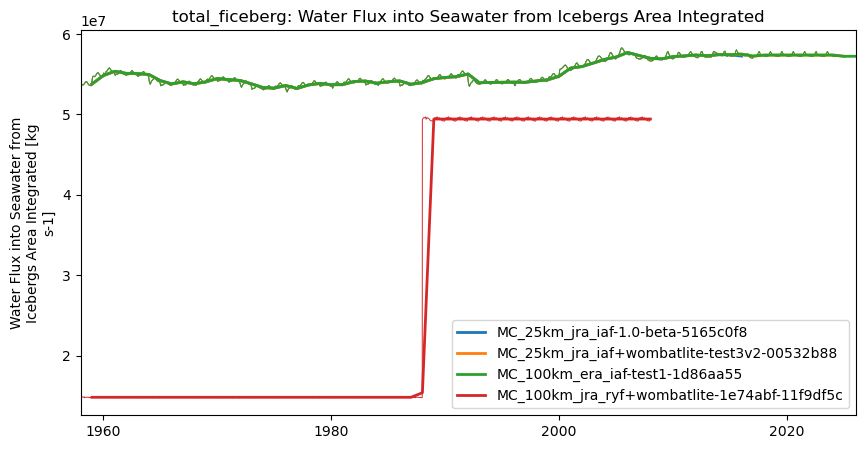

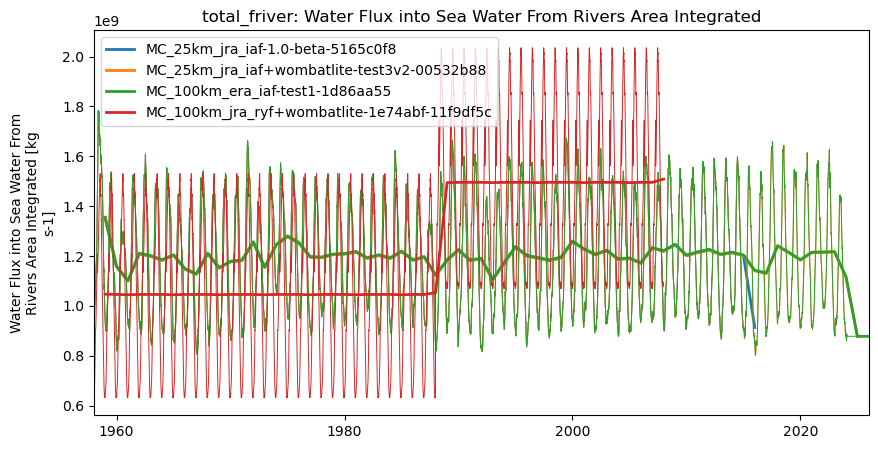

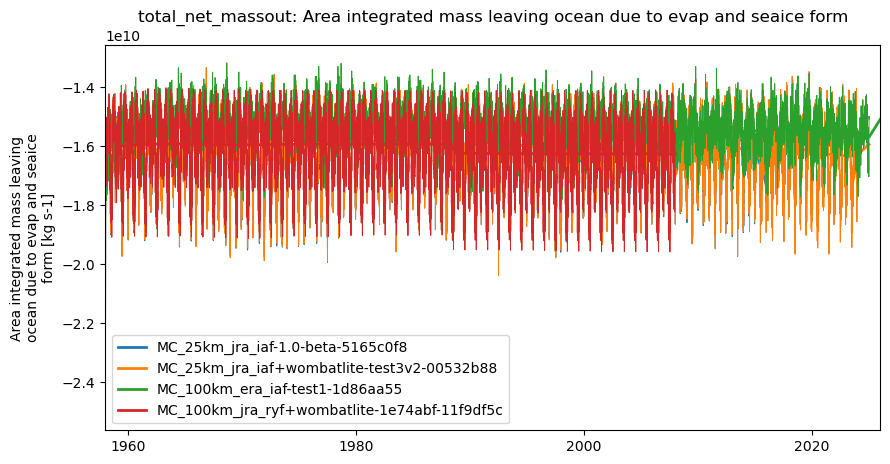

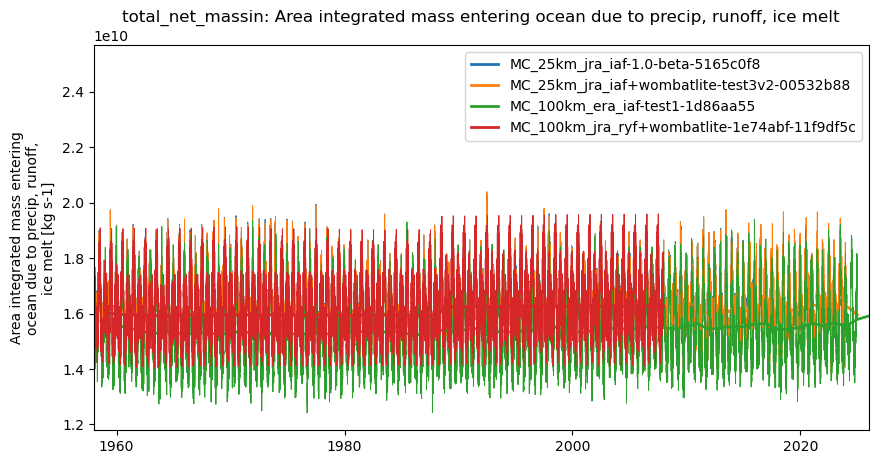

In [20]:
for k, d in data.items():
    print(k)
    fname = thisdir+k+'_'+list(d.values())[-1][k].attrs['long_name'].replace(' ', '_').replace('/','_')+'.png'
    # print(fname)
    if False: #os.path.isfile(fname):
        print(f'---- skipping existing file {fname}')
    else:
        plt.figure(figsize=(10,5))
        ax = plt.subplot(111)
        for n, ds in d.items():
            dat = ds[k].sel(time=trange)
            if dat.cell_methods.find('time: mean') >= 0:
                # calculate spatial average if needed
                if 'depth' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y', 'Z'])
                elif 'longitude' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y'])
            elif dat.cell_methods.find('time: max') >= 0:
                dat = dat.cf.max(dim=['longitude', 'latitude'])
            elif dat.cell_methods.find('time: min') >= 0:
                dat = dat.cf.min(dim=['longitude', 'latitude'])
            # dat = dat - dat.isel(time=0)
            dat.load()
            # if int((dat.time[1]-dat.time[0]).values/1e9/60/60/24) == 1:
            #     label = 'daily'
            # else:
            #     label = 'monthly mean' # possible BUG: plausible guess
            # p = dat.plot(label=' '.join([n, label]), linewidth=1)
            p = dat.plot(linewidth=.7)
            dat.cf.resample(time='1YE').mean('time').plot(
                color=p[-1].get_color(),
                linewidth=2,
                label=n
            )
            # dat.cf.rolling(time=12, center=True).mean('time').plot()
            # dat.cf.rolling(time='1YE', center=True).mean('time').plot()
        # NB: title from first item (OM3), but y axis label from last item (may be OM2)
        # plt.title(k+': '+list(d.values())[0][k].attrs['long_name'])
        plt.title(f'{k}: {dat.attrs["long_name"]}')
        plt.xlabel('')
        plt.autoscale(enable=True, axis='x', tight=True)
        plt.legend()
        # # Shrink current axis's height from the bottom
        # box = ax.get_position()
        # ax.set_position([box.x0, box.y0 + box.height * 0.4,
        #                  box.width, box.height * 0.6])
        # # Put a legend below current axis
        # ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
        # # try:
        #     plt.savefig(fname, dpi=150)
        #     print(f'saved {fname}')
        # except FileNotFoundError:
        #     print(f'*** FileNotFoundError when saving {fname}')
        # break
    mkmd.savefig(plt.gcf(), "Timeseries", "ACCESS-OM3 global model timeseries. [GitHub issue: Global average annual mean time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/3)")

soga


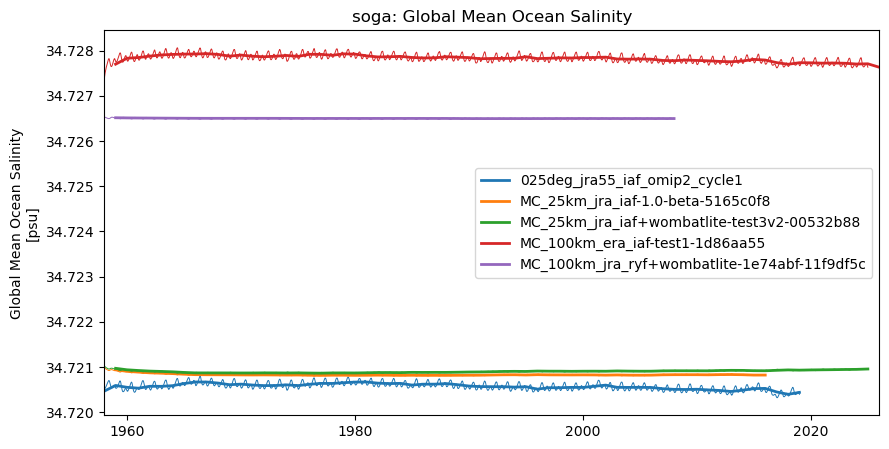

In [21]:
# just plot soga, omitting 25km-iaf-test-for-AK-expt-7df5ef4c
for k, d in data.items():
    if k != "soga":
        continue
    print(k)
    fname = thisdir+k+'_'+list(d.values())[-1][k].attrs['long_name'].replace(' ', '_').replace('/','_')+'.png'
    # print(fname)
    if False: #os.path.isfile(fname):
        print(f'---- skipping existing file {fname}')
    else:
        plt.figure(figsize=(10,5))
        ax = plt.subplot(111)
        for n, ds in d.items():
            if n == "25km-iaf-test-for-AK-expt-7df5ef4c":
                continue
            dat = ds[k].sel(time=trange)
            if dat.cell_methods.find('time: mean') >= 0:
                # calculate spatial average if needed
                if 'depth' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y', 'Z'])
                elif 'longitude' in dat.cf.coords: # https://xgcm.readthedocs.io/en/latest/grid_metrics.html?highlight=average#Grid-aware-(weighted)-average
                    dat = grid.average(dat, ['X', 'Y'])
            elif dat.cell_methods.find('time: max') >= 0:
                dat = dat.cf.max(dim=['longitude', 'latitude'])
            elif dat.cell_methods.find('time: min') >= 0:
                dat = dat.cf.min(dim=['longitude', 'latitude'])
            # dat = dat - dat.isel(time=0)
            dat.load()
            # if int((dat.time[1]-dat.time[0]).values/1e9/60/60/24) == 1:
            #     label = 'daily'
            # else:
            #     label = 'monthly mean' # possible BUG: plausible guess
            # p = dat.plot(label=' '.join([n, label]), linewidth=1)
            p = dat.plot(linewidth=.7)
            dat.cf.resample(time='1YE').mean('time').plot(
                color=p[-1].get_color(),
                linewidth=2,
                label=n
            )
            # dat.cf.rolling(time=12, center=True).mean('time').plot()
            # dat.cf.rolling(time='1YE', center=True).mean('time').plot()
        # NB: title from first item (OM3), but y axis label from last item (may be OM2)
        # plt.title(k+': '+list(d.values())[0][k].attrs['long_name'])
        plt.title(f'{k}: {dat.attrs["long_name"]}')
        plt.xlabel('')
        plt.autoscale(enable=True, axis='x', tight=True)
        plt.legend()
        # # Shrink current axis's height from the bottom
        # box = ax.get_position()
        # ax.set_position([box.x0, box.y0 + box.height * 0.4,
        #                  box.width, box.height * 0.6])
        # # Put a legend below current axis
        # ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
        # # try:
        #     plt.savefig(fname, dpi=150)
        #     print(f'saved {fname}')
        # except FileNotFoundError:
        #     print(f'*** FileNotFoundError when saving {fname}')
        # break

## Water balance checks

https://github.com/ACCESS-NRI/access-om3-configs/issues/920

In [22]:
esm_name = get_exptname_from_path(esm_file)
esm_name

'MC_100km_era_iaf-test1-1d86aa55'

In [23]:
masked_areacello = static['areacello'] + 0*data['tos_max'][esm_name].tos_max.isel(time=0)

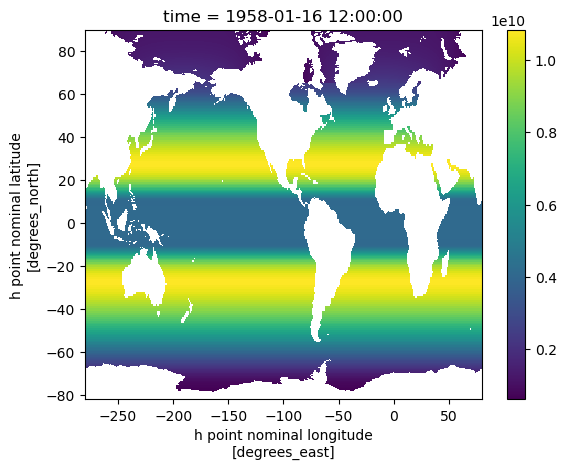

In [24]:
masked_areacello.plot()

In [25]:
total_ocean_area = masked_areacello.sum().load()

In [26]:
total_fsitherm = data['total_fsitherm'][esm_name]['total_fsitherm'].load()

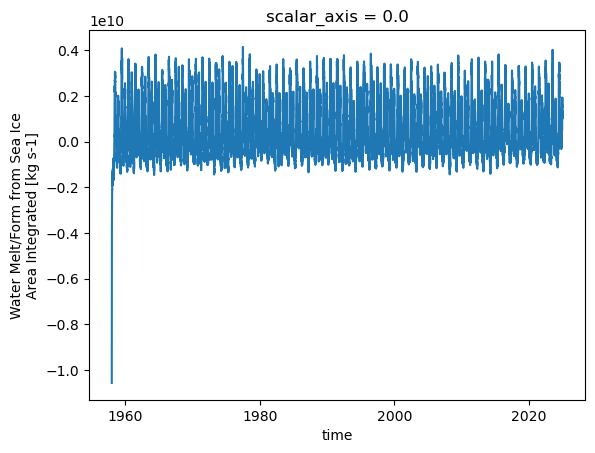

In [27]:
total_fsitherm.plot()

In [28]:
try:
    net_fresh_water_global_adjustment = (data['net_fresh_water_global_adjustment'][esm_name]['net_fresh_water_global_adjustment'] * total_ocean_area).load()
    net_fresh_water_global_adjustment.plot()
    (net_fresh_water_global_adjustment - total_fsitherm).plot()
except KeyError:
    pass